# 04 — Hipótesis H1–H4 con datos de LMB

**Estrategia principal: comparar al MISMO pitcher, con el MISMO pitch y en la MISMA temporada** en distintos
ambientes. 665 pitchers lanzaron en las 3 categorías de altitud. Así quitamos el sesgo de "quién lanza dónde"
(los pitchers locales de cada parque son distintos).

Límite: los rivales también cambian según el parque. Esto es evidencia exploratoria para decidir qué meter al modelo,
no una estimación causal final.

In [1]:
import os, sys; sys.path.insert(0, ".."); os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
from src.data_prep import build_dataset, PROCESSED_PATH, ALTITUDE_ORDER
from src.viz import set_style, savefig, ALT_COLORS, ALT_LABELS, PITCH_ORDER, CAT, INK2, MUTED
set_style(); pd.set_option("display.width", 200)
df = pd.read_parquet(PROCESSED_PATH) if PROCESSED_PATH.exists() else build_dataset(save=True)[0]
u = df[df.usable_stuff & df.altitude_category.notna() & df.pitcher_anon_id.notna()].copy()
u["env"] = u.altitude_category.astype(str)
KEY = ["pitcher_anon_id", "pitch_type", "year"]
rng = np.random.default_rng(42)
MIN_GROUPS = 20  # mínimo de (pitcher, pitch, temporada) emparejados para reportar un tipo de pitch

def boot_ci(x, w=None, n=1000):
    x = np.asarray(x, float); w = np.ones_like(x) if w is None else np.asarray(w, float)
    idx = rng.integers(0, len(x), (n, len(x)))
    stats = (x[idx] * w[idx]).sum(1) / w[idx].sum(1)
    return np.average(x, weights=w), *np.percentile(stats, [2.5, 97.5])

def paired(d, env_a="No Altitude", env_b="Extreme Altitude", min_n=30, cols=()):
    """Medias por (pitcher, pitch, temporada) en cada ambiente; solo grupos con >= min_n pitches en ambos."""
    g = d[d.env.isin([env_a, env_b])].groupby(KEY + ["env"])
    agg = g[list(cols)].mean().join(g.size().rename("n"))
    w = agg.unstack("env").dropna()
    w = w[(w[("n", env_a)] >= min_n) & (w[("n", env_b)] >= min_n)]
    return w

## H1 — La baja densidad reduce el movimiento inducido por spin
Física esperada: Magnus ∝ densidad → todos los pitches **se acercan a "cero movimiento inducido"**. El four-seam pierde
ride, el sinker y el changeup pierden caída inducida y run, y la curva cae menos. La magnitud esperada es del orden
de la densidad relativa (≈0.82 en Extreme).

In [2]:
mcols = ["InducedVertBreak", "hb_arm", "total_movement", "RelSpeed", "SpinRate", "speed_drop_pct"]
w = paired(u, cols=mcols)
rows = []
for pt in PITCH_ORDER:
    s = w.xs(pt, level="pitch_type") if pt in w.index.get_level_values("pitch_type") else None
    if s is None or len(s) < MIN_GROUPS: continue
    wt = np.minimum(s[("n", "No Altitude")], s[("n", "Extreme Altitude")])
    r = {"pitch_type": pt, "grupos": len(s)}
    for c in ["InducedVertBreak", "hb_arm", "total_movement", "RelSpeed", "SpinRate"]:
        m, lo, hi = boot_ci(s[(c, "Extreme Altitude")] - s[(c, "No Altitude")], wt)
        r[f"Δ {c}"], r[f"Δ {c} lo"], r[f"Δ {c} hi"] = m, lo, hi
    r["ratio movimiento total"] = np.average(s[("total_movement", "Extreme Altitude")] / s[("total_movement", "No Altitude")], weights=wt)
    r["mov. sin altitud (pulg.)"] = np.average(s[("total_movement", "No Altitude")], weights=wt)
    rows.append(r)
h1 = pd.DataFrame(rows).set_index("pitch_type")
h1[["grupos", "mov. sin altitud (pulg.)", "Δ InducedVertBreak", "Δ hb_arm", "Δ total_movement", "ratio movimiento total", "Δ RelSpeed", "Δ SpinRate"]].round(2)

,grupos,mov. sin altitud (pulg.),Δ InducedVertBreak,Δ hb_arm,Δ total_movement,ratio movimiento total,Δ RelSpeed,Δ SpinRate
pitch_type,,,,,,,,
Four-Seam,447,19.95,-3.88,-2.78,-4.77,0.76,0.09,-4.32
Sinker,177,19.58,-2.21,-4.43,-5.10,0.74,0.05,-8.77
Cutter,28,11.55,-2.43,-0.21,-2.33,0.80,0.39,-23.19
Slider,266,8.11,-0.79,1.18,-1.80,0.80,0.46,34.67
Curveball,59,15.43,1.92,3.42,-4.04,0.75,0.17,9.85
Changeup,99,16.85,-2.18,-4.47,-5.06,0.70,-0.32,-23.36


Δ = Extreme − No (mismo pitcher, mismo pitch, misma temporada). La velocidad y el spin casi no cambian (el pitcher es
el mismo), pero **el movimiento sí**. Si el ratio de movimiento ≈ 0.8, el efecto es del tamaño que predice la física.

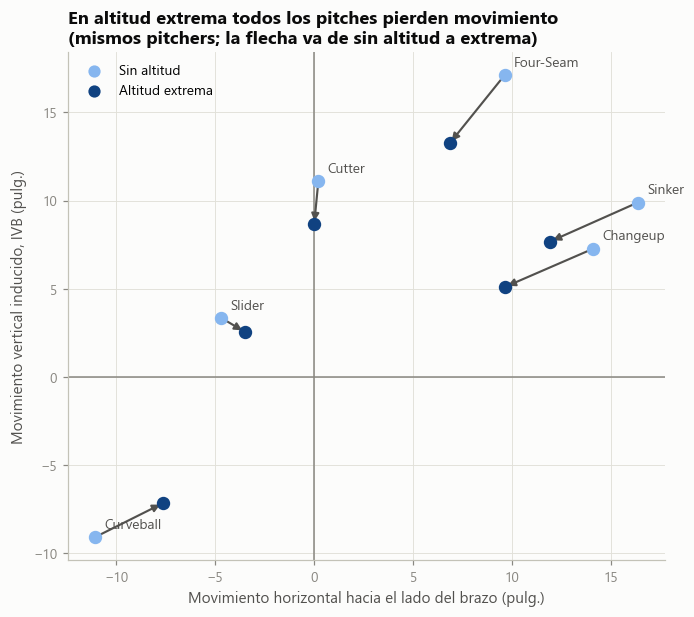

In [3]:
# Mapa de movimiento: posición media (HB lado brazo, IVB) de cada pitch en cada ambiente, mismos pitchers
pos = []
for pt in PITCH_ORDER:
    if pt not in w.index.get_level_values("pitch_type"): continue
    s = w.xs(pt, level="pitch_type")
    wt = np.minimum(s[("n", "No Altitude")], s[("n", "Extreme Altitude")])
    for e in ["No Altitude", "Extreme Altitude"]:
        pos.append({"pt": pt, "env": e, "hb": np.average(s[("hb_arm", e)], weights=wt), "ivb": np.average(s[("InducedVertBreak", e)], weights=wt)})
pos = pd.DataFrame(pos).set_index(["pt", "env"])

fig, ax = plt.subplots(figsize=(7, 6))
ax.axhline(0, color=MUTED, lw=1); ax.axvline(0, color=MUTED, lw=1)
for pt in h1.index:
    a, b = pos.loc[(pt, "No Altitude")], pos.loc[(pt, "Extreme Altitude")]
    ax.annotate("", xy=(b.hb, b.ivb), xytext=(a.hb, a.ivb), arrowprops=dict(arrowstyle="-|>", color=INK2, lw=1.4))
    ax.scatter(a.hb, a.ivb, s=60, color=ALT_COLORS["No Altitude"], zorder=3)
    ax.scatter(b.hb, b.ivb, s=60, color=ALT_COLORS["Extreme Altitude"], zorder=3)
    ax.annotate(pt, (a.hb, a.ivb), xytext=(6, 6), textcoords="offset points", fontsize=9, color=INK2)
ax.scatter([], [], color=ALT_COLORS["No Altitude"], label="Sin altitud"); ax.scatter([], [], color=ALT_COLORS["Extreme Altitude"], label="Altitud extrema")
ax.legend(loc="upper left")
ax.set_xlabel("Movimiento horizontal hacia el lado del brazo (pulg.)"); ax.set_ylabel("Movimiento vertical inducido, IVB (pulg.)")
ax.set_title("En altitud extrema todos los pitches pierden movimiento\n(mismos pitchers; la flecha va de sin altitud a extrema)")
savefig(fig, "04_H1_mapa_movimiento"); plt.show()

### Dosis-respuesta: movimiento vs densidad del aire (continuo)
Dentro de cada (pitcher, pitch, temporada), regresamos el movimiento contra `air_density_ratio` del juego.
La pendiente dice **cuántas pulgadas se pierden por cada 10% menos de densidad**.

In [4]:
v = u.dropna(subset=["air_density_ratio"]).copy()
for c in ["InducedVertBreak", "hb_arm", "total_movement", "air_density_ratio"]:
    v[c + "_d"] = v[c] - v.groupby(KEY)[c].transform("mean")
sl = []
for pt in PITCH_ORDER:
    s = v[v.pitch_type == pt]
    x = s.air_density_ratio_d
    row = {"pitch_type": pt}
    for c in ["InducedVertBreak", "hb_arm", "total_movement"]:
        row[f"pulg. por +10% densidad ({c})"] = 0.1 * (x * s[c + "_d"]).sum() / (x ** 2).sum()
    sl.append(row)
pd.DataFrame(sl).set_index("pitch_type").round(2)

,pulg. por +10% densidad (InducedVertBreak),pulg. por +10% densidad (hb_arm),pulg. por +10% densidad (total_movement)
pitch_type,,,
Four-Seam,1.92,1.27,2.32
Sinker,1.11,1.99,2.36
Cutter,1.17,0.19,1.15
Slider,0.41,-0.62,0.87
Curveball,-0.75,-1.45,1.70
Changeup,0.99,2.06,2.33
Splitter,0.42,1.61,1.81


## H2 — Los pitches de diferencial de velocidad ganan valor relativo
Si el changeup/splitter engaña por velocidad más que por movimiento, debería **perder menos** que slider y curva en
altitud. Medimos el cambio (Extreme − No) del mismo pitcher en whiff/swing, CSW y run value por 100 pitches
(positivo = mejor para el pitcher).

Como en altitud *todos* los pitches empeoran (más hits), lo que importa es la comparación **entre tipos de pitch**.

In [5]:
ucols = ["whiff", "swing", "csw", "delta_run_exp", "velo_diff_vs_fb", "ivb_diff_vs_fb", "hb_diff_vs_fb"]
u["whiff_sw"] = np.where(u.swing, u.whiff.astype(float), np.nan)
w2 = paired(u, cols=ucols + ["whiff_sw"])
rows = []
for pt in PITCH_ORDER:
    if pt not in w2.index.get_level_values("pitch_type"): continue
    s = w2.xs(pt, level="pitch_type")
    if len(s) < MIN_GROUPS: continue
    wt = np.minimum(s[("n", "No Altitude")], s[("n", "Extreme Altitude")])
    r = {"pitch_type": pt, "grupos": len(s)}
    for c, lab, k in [("whiff_sw", "Δ whiff/swing", 1), ("csw", "Δ CSW", 1), ("delta_run_exp", "Δ RV/100 pitcher", -100)]:
        m, lo, hi = boot_ci(k * (s[(c, "Extreme Altitude")] - s[(c, "No Altitude")]), wt)
        r[lab], r[lab + " lo"], r[lab + " hi"] = m, min(lo, hi), max(lo, hi)
    for c in ["velo_diff_vs_fb", "ivb_diff_vs_fb", "hb_diff_vs_fb"]:
        r[f"Δ {c}"] = np.average(s[(c, "Extreme Altitude")] - s[(c, "No Altitude")], weights=wt)
    rows.append(r)
h2 = pd.DataFrame(rows).set_index("pitch_type")
h2[["grupos", "Δ whiff/swing", "Δ CSW", "Δ RV/100 pitcher", "Δ velo_diff_vs_fb", "Δ ivb_diff_vs_fb", "Δ hb_diff_vs_fb"]].round(3)

,grupos,Δ whiff/swing,Δ CSW,Δ RV/100 pitcher,Δ velo_diff_vs_fb,Δ ivb_diff_vs_fb,Δ hb_diff_vs_fb
pitch_type,,,,,,,
Four-Seam,447,-0.032,-0.023,-1.376,-0.008,-0.013,0.077
Sinker,177,-0.019,-0.019,-1.762,0.055,0.124,-0.193
Cutter,28,0.029,0.010,-0.682,0.060,-0.007,1.027
Slider,266,-0.024,-0.015,-1.071,0.368,2.244,4.168
Curveball,59,0.000,0.010,-0.687,-0.006,5.232,6.094
Changeup,99,-0.022,-0.028,-2.445,-0.354,0.511,-1.629


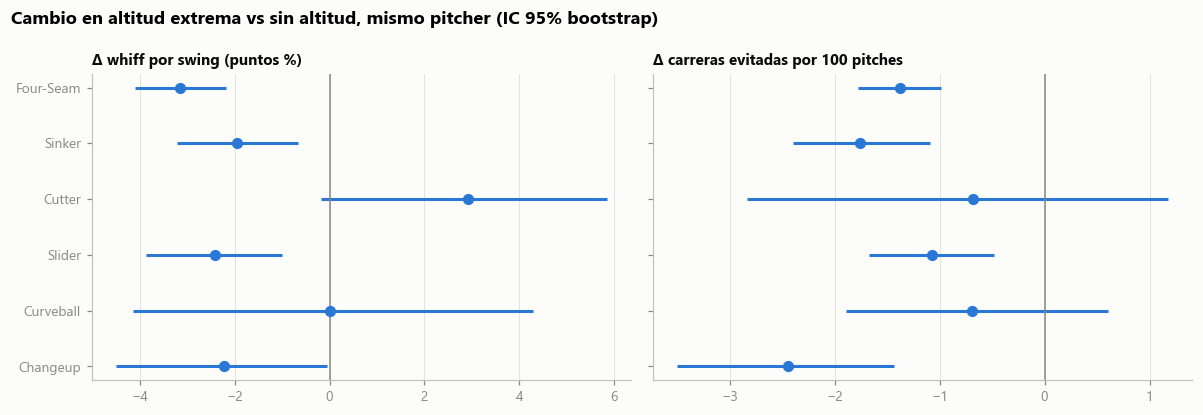

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
pts = list(h2.index); y = np.arange(len(pts))
for ax, lab, fmt, title in [(axes[0], "Δ whiff/swing", 100, "Δ whiff por swing (puntos %)"),
                            (axes[1], "Δ RV/100 pitcher", 1, "Δ carreras evitadas por 100 pitches")]:
    m, lo, hi = h2[lab] * fmt, h2[lab + " lo"] * fmt, h2[lab + " hi"] * fmt
    ax.hlines(y, lo, hi, color=CAT[0], lw=2)
    ax.scatter(m, y, color=CAT[0], s=40, zorder=3)
    ax.axvline(0, color=MUTED, lw=1); ax.set_title(title, fontsize=10); ax.grid(axis="y", visible=False)
axes[0].set_yticks(y); axes[0].set_yticklabels(pts); axes[0].invert_yaxis()
fig.suptitle("Cambio en altitud extrema vs sin altitud, mismo pitcher (IC 95% bootstrap)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
savefig(fig, "04_H2_cambio_resultados"); plt.show()

**Cómo leerlo:** valores a la izquierda de 0 = el pitch rinde peor en altitud. H2 se apoya si Changeup/Splitter
quedan más cerca de 0 que Slider/Curveball. Las columnas `Δ *_diff_vs_fb` muestran si el **diferencial contra el
fastball** se mantiene (velocidad) o se encoge (movimiento) en altitud.

## H3 — Los pitchers de rolling valen más en altitud
Primero, cuánto vale cada tipo de batazo en cada ambiente. Si el fly ball "cuesta" mucho más en altitud que el rolling,
inducir rollings vale más ahí.

In [7]:
bip = u[u.in_play & u.hit_type.notna() & u.hit_type.ne("Bunt")]
bb = bip.groupby(["hit_type", "env"]).agg(n=("delta_run_exp", "size"), rv=("delta_run_exp", "mean"),
                                         hit=("is_hit", "mean"), hr=("home_run", "mean")).unstack("env")
bb = bb.reindex(["GroundBall", "LineDrive", "FlyBall", "Popup"])
bb.round(3)

n                                           rv                                          hit                                           hr                            
env        Extreme Altitude Medium Altitude No Altitude Extreme Altitude Medium Altitude No Altitude Extreme Altitude Medium Altitude No Altitude Extreme Altitude Medium Altitude No Altitude
hit_type                                                                                                                                                                                      
GroundBall            15351           12114       21038           -0.058          -0.065      -0.098            0.341           0.346       0.308            0.000           0.000       0.000
LineDrive              7221            6071       11026            0.260           0.236       0.187            0.692           0.684       0.644            0.042           0.043       0.049
FlyBall                6858            5913       10899            0.214           0.201       0.064            0.346           0.320       0.248            0.163           0.158       0.124
Popup                  2613            2205        4582           -0.238          -0.258      -0.263            0.046           0.036       0.019            0.002           0.000       0.000

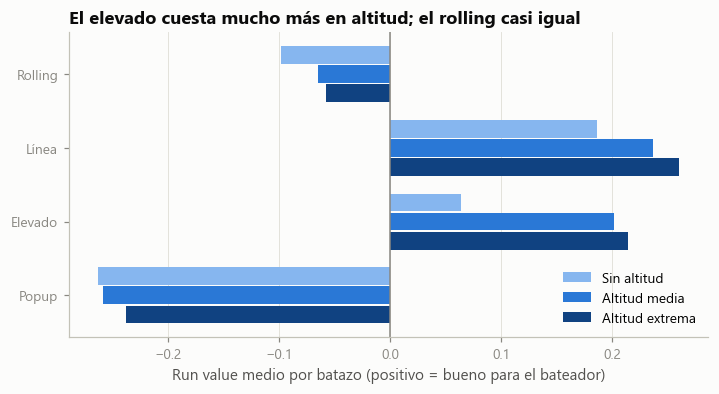

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
types = ["GroundBall", "LineDrive", "FlyBall", "Popup"]; y = np.arange(len(types))
for k, e in enumerate(ALTITUDE_ORDER):
    vals = bb[("rv", e)].reindex(types)
    ax.barh(y + (k - 1) * 0.26, vals, height=0.24, color=ALT_COLORS[e], label=ALT_LABELS[e])
ax.set_yticks(y); ax.set_yticklabels(["Rolling", "Línea", "Elevado", "Popup"]); ax.invert_yaxis()
ax.axvline(0, color=MUTED, lw=1); ax.grid(axis="y", visible=False)
ax.set_xlabel("Run value medio por batazo (positivo = bueno para el bateador)")
ax.set_title("El elevado cuesta mucho más en altitud; el rolling casi igual")
ax.legend(loc="lower right")
savefig(fig, "04_H3_valor_batazo"); plt.show()

Ahora a nivel pitcher-temporada-ambiente: ¿la relación entre GB% y run value por batazo es más fuerte en altitud?
Regresión ponderada `rv_por_batazo ~ GB% × ambiente` (pesos = batazos).

In [9]:
pp = bip.groupby(["pitcher_anon_id", "year", "env"]).agg(n=("delta_run_exp", "size"), rv=("delta_run_exp", "mean"),
                                                       gb=("hit_type", lambda s: (s == "GroundBall").mean())).reset_index()
pp = pp[pp.n >= 30]
pp["env"] = pd.Categorical(pp.env, ALTITUDE_ORDER)
m3 = smf.wls("rv ~ gb * C(env, Treatment('No Altitude'))", data=pp, weights=pp.n).fit(cov_type="HC1")
print(m3.summary().tables[1])
slopes = {e: m3.params["gb"] + (m3.params.get(f"gb:C(env, Treatment('No Altitude'))[T.{e}]", 0.0)) for e in ALTITUDE_ORDER}
print("\nPendiente: cambio en run value por batazo por cada +10 pts de GB%:", {k: round(0.1 * v, 4) for k, v in slopes.items()})

                                                              coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   0.0388      0.015      2.502      0.012       0.008       0.069
C(env, Treatment('No Altitude'))[T.Medium Altitude]         0.0449      0.033      1.359      0.174      -0.020       0.110
C(env, Treatment('No Altitude'))[T.Extreme Altitude]        0.0747      0.031      2.402      0.016       0.014       0.136
gb                                                         -0.1340      0.034     -3.935      0.000      -0.201      -0.067
gb:C(env, Treatment('No Altitude'))[T.Medium Altitude]      0.0251      0.071      0.351      0.726      -0.115       0.165
gb:C(env, Treatment('No Altitude'))[T.Extreme Altitude]    -0.0128      0.065     -0.197      0.844      -0.140       0.114

Pendien

**Cómo leerlo:** una pendiente más negativa en altitud significa que cada punto extra de rolling **ahorra más
carreras** ahí → apoya H3. Revisar también el BABIP: según la SABR, la mayoría de las carreras extra en altitud
vienen de hits, no de jonrones.

## H4 — El spin rate solo no basta ("shape over spin")
Por tipo de pitch, ¿qué tan bien predicen el **whiff en swings** distintos conjuntos de variables? Usamos un modelo
de gradient boosting chico con validación cruzada **agrupada por pitcher** (generaliza a pitchers no vistos).
Métrica: AUC (0.5 = azar).

In [10]:
sets = {
    "solo spin": ["SpinRate"],
    "spin + velo": ["SpinRate", "RelSpeed"],
    "movimiento + velo": ["InducedVertBreak", "hb_arm", "RelSpeed"],
    "físico completo": ["InducedVertBreak", "hb_arm", "RelSpeed", "SpinRate", "SpinAxis", "RelHeight", "rel_side_arm",
                        "Extension", "VertApprAngle", "velo_diff_vs_fb", "ivb_diff_vs_fb", "hb_diff_vs_fb"],
}
sw = u[u.swing]
res = []
for pt in PITCH_ORDER:
    s = sw[sw.pitch_type == pt]
    if len(s) > 40000: s = s.sample(40000, random_state=0)
    if len(s) < 2000: continue
    yv, groups = s.whiff.astype(int).to_numpy(), s.pitcher_anon_id.to_numpy()
    row = {"pitch_type": pt, "swings": len(s)}
    for name, cols in sets.items():
        X = s[cols].to_numpy()
        p = cross_val_predict(HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08, max_leaf_nodes=15),
                              X, yv, groups=groups, cv=GroupKFold(4), method="predict_proba")[:, 1]
        row[name] = roc_auc_score(yv, p)
    res.append(row)
h4 = pd.DataFrame(res).set_index("pitch_type")
h4.round(3)

,swings,solo spin,spin + velo,movimiento + velo,físico completo
pitch_type,,,,,
Four-Seam,40000,0.533,0.551,0.586,0.682
Sinker,40000,0.504,0.512,0.541,0.665
Cutter,12735,0.518,0.516,0.570,0.666
Slider,40000,0.516,0.520,0.553,0.723
Curveball,22901,0.507,0.534,0.550,0.751
Changeup,37994,0.510,0.551,0.556,0.717
Splitter,3675,0.502,0.513,0.522,0.672


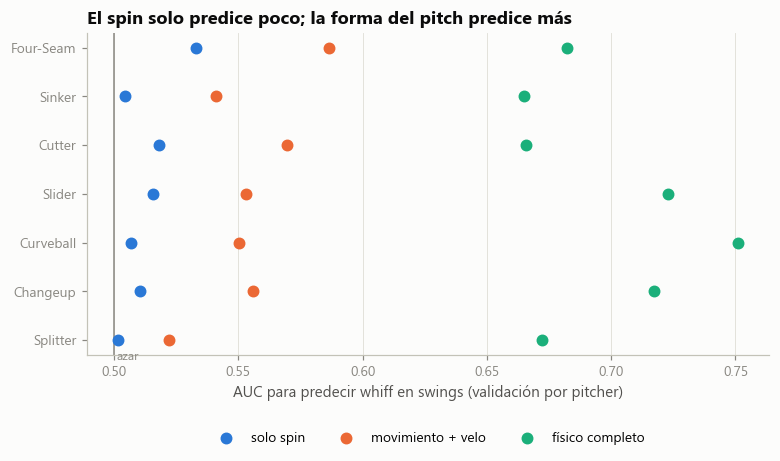

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(h4))
for k, (name, col) in enumerate(zip(["solo spin", "movimiento + velo", "físico completo"], CAT)):
    ax.scatter(h4[name], y, s=46, color=col, label=name, zorder=3)
ax.set_yticks(y); ax.set_yticklabels(h4.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.axvline(0.5, color=MUTED, lw=1); ax.text(0.501, len(h4) - 0.6, "azar", color=MUTED, fontsize=8)
ax.set_xlabel("AUC para predecir whiff en swings (validación por pitcher)")
ax.set_title("El spin solo predice poco; la forma del pitch predice más")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
savefig(fig, "04_H4_spin_vs_forma"); plt.show()

### Mismo spin, menos movimiento en altitud
Con los mismos pitchers de H1: el spin (rpm) prácticamente no cambia entre ambientes, pero el movimiento que produce
cada 1,000 rpm sí. Un mismo "rpm" vale distinto en Harp Helú → el modelo debe usar movimiento observado + ambiente.

*(Comparar pendientes spin→movimiento ENTRE pitchers no sirve: lo confunde la eficiencia de spin de cada pitcher.)*

In [12]:
rows = []
for pt in h1.index:
    s = w.xs(pt, level="pitch_type")
    wt = np.minimum(s[("n", "No Altitude")], s[("n", "Extreme Altitude")])
    r = {"pitch_type": pt}
    for e in ["No Altitude", "Extreme Altitude"]:
        r[f"rpm ({ALT_LABELS[e]})"] = np.average(s[("SpinRate", e)], weights=wt)
        r[f"pulg. por 1,000 rpm ({ALT_LABELS[e]})"] = np.average(1000 * s[("total_movement", e)] / s[("SpinRate", e)], weights=wt)
    rows.append(r)
pd.DataFrame(rows).set_index("pitch_type").round(2)

,rpm (Sin altitud),"pulg. por 1,000 rpm (Sin altitud)",rpm (Altitud extrema),"pulg. por 1,000 rpm (Altitud extrema)"
pitch_type,,,,
Four-Seam,2328.90,8.58,2324.58,6.54
Sinker,2269.75,8.64,2260.98,6.41
Cutter,2396.75,4.84,2373.56,3.91
Slider,2422.59,3.33,2457.26,2.56
Curveball,2596.31,5.90,2606.16,4.33
Changeup,1883.97,8.98,1860.60,6.34


## Resumen para el equipo
Ver `docs/eda_hallazgos.md`, que resume estas tablas en lenguaje de béisbol.